# 1D UMAP Ideological Projection on Political Embeddings

This notebook projects dense $d=768$ political sentence embeddings from `data/out/political_embeddings.parquet` onto a single continuous dimension (`n_components=1`) using **UMAP (Uniform Manifold Approximation and Projection)**.

### Why 1D UMAP?
* In political science, ideology is often structured along a dominant 1-dimensional latent spectrum (Left $\leftrightarrow$ Right / Liberal $\leftrightarrow$ Conservative).
* While PCA finds linear directions of maximal variance, UMAP preserves local and non-linear topological manifolds.
* Fitting `n_components=1` directly models every video as a continuous scalar coordinate on this ideological manifold.

### Pipeline:
1. **Load Embeddings**: Load the 111,967 political embeddings from `data/out/political_embeddings.parquet`.
2. **Fit 1D UMAP**: Run UMAP with `n_components=1` and cosine metric.
3. **Orientation Alignment**: Automatically orient the 1D axis so positive values align with Right-wing slant and negative with Left-wing slant.
4. **Correlation with Slant**: Compute Pearson $r$ and Spearman $\rho$ against Haroon ground-truth slants.
5. **Visualizations**: 1D jitter scatter plot, channel KDE ridge plots, and correlation distribution.
6. **Inspection**: Sample extreme Left, Centrist, and Right videos along the 1D axis.

In [1]:
import sys
from pathlib import Path

# Add src directory to path
ROOT = Path("../")
sys.path.insert(0, str(ROOT / "src"))

import polars as pl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import umap

from config import OUT_DIR

# Aesthetics configuration
sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["figure.dpi"] = 120

/Users/gustavidunsloth/Documents/Data Science/youtube-ideology-classifier/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load Precomputed Political Embeddings
Load `political_embeddings.parquet` produced by the embedder pipeline.

In [2]:
embeddings_path = OUT_DIR / "political_embeddings.parquet"
print(f"Reading embeddings from: {embeddings_path}")

df_raw = pl.read_parquet(embeddings_path)
print(f"Total videos loaded: {len(df_raw):,}")
df_raw.select(["id", "channel", "title", "slant", "political_saliency"]).head(5)

Reading embeddings from: /Users/gustavidunsloth/Documents/Data Science/youtube-ideology-classifier/nbs/../data/out/political_embeddings.parquet
Total videos loaded: 111,967


id,channel,title,slant,political_saliency
str,str,str,f64,f64
"""oWZEHs5Covo""","""Vital Information""","""The narrative is crumbling.""",-0.230769,1.0
"""_XOerG5R290""","""Dr. John Campbell""","""South Africa Omicron""",0.15789,0.5
"""rDujVSXYcrY""","""Jimmy Kimmel Live""","""President Obama Says First Lad…",-0.56098,0.5
"""uNXDplgft_g""","""Atun-Shei Films""","""King Philip's War: The Most Im…",-0.61644,0.8
"""0YCk1FyxC68""","""MyNIRS""","""Building Safeguards into Pensi…",-0.666667,0.5


## 2. Prepare Embedding Matrix
Optionally choose a sample size for faster iteration (e.g., `SAMPLE_SIZE = 25000`), or set to `None` to compute UMAP across all 111,967 videos.

In [3]:
# Set SAMPLE_SIZE = None to run on all 111,967 videos, or specify an integer for rapid iteration
SAMPLE_SIZE = None  # e.g., 25000 or None for full dataset
SEED = 42

if SAMPLE_SIZE is not None and SAMPLE_SIZE < len(df_raw):
    df_subset = df_raw.sample(SAMPLE_SIZE, seed=SEED)
    print(f"Sampled {len(df_subset):,} videos for UMAP analysis.")
else:
    df_subset = df_raw
    print(f"Using full dataset: {len(df_subset):,} videos.")

# Convert list of embeddings into a 2D numpy array (N, 768)
print("Converting embeddings to NumPy matrix...")
X = np.array(df_subset["embedding"].to_list(), dtype=np.float32)
print(f"Feature matrix shape: {X.shape}")

Using full dataset: 111,967 videos.
Converting embeddings to NumPy matrix...
Feature matrix shape: (111967, 768)


## 3. Fit 1D UMAP Manifold (`n_components=1`)
Fit UMAP with `n_components=1` using `metric='cosine'` (ideal for normalized sentence embeddings).

In [4]:
print("Fitting 1D UMAP (n_components=1, metric='cosine')...")

reducer = umap.UMAP(
    n_components=1,
    metric="cosine",
    n_neighbors=30,
    min_dist=0.1,
    random_state=SEED,
    verbose=True
)

umap_1d_raw = reducer.fit_transform(X).ravel()
print("UMAP fitting complete!")

# Create analysis DataFrame
plot_df = df_subset.select(["id", "channel", "title", "slant", "political_saliency"]).to_pandas()

# Orient 1D UMAP so that it correlates positively with ideological slant (+ = Right, - = Left)
corr_initial, _ = stats.spearmanr(umap_1d_raw, plot_df["slant"].fillna(0))
if corr_initial < 0:
    print(f"Flipping 1D axis orientation (initial Spearman r={corr_initial:.3f}) so Right is positive...")
    umap_1d = -umap_1d_raw
else:
    umap_1d = umap_1d_raw

# Normalize to [-1.0, 1.0] for intuitive interpretation
min_val, max_val = umap_1d.min(), umap_1d.max()
plot_df["umap_1d"] = 2.0 * (umap_1d - min_val) / (max_val - min_val) - 1.0

print(f"1D UMAP range: [{plot_df['umap_1d'].min():.3f}, {plot_df['umap_1d'].max():.3f}]")
plot_df.head(5)

Fitting 1D UMAP (n_components=1, metric='cosine')...
UMAP(angular_rp_forest=True, metric='cosine', n_components=1, n_jobs=1, n_neighbors=30, random_state=42, verbose=True)
Fri Oct 23 10:18:02 2026 Construct fuzzy simplicial set
Fri Oct 23 10:18:03 2026 Finding Nearest Neighbors


/Users/gustavidunsloth/Documents/Data Science/youtube-ideology-classifier/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Fri Oct 23 10:18:03 2026 Building RP forest with 22 trees
Fri Oct 23 10:18:11 2026 NN descent for 17 iterations
	 1  /  17
	 2  /  17
	 3  /  17
	Stopping threshold met -- exiting after 3 iterations
Fri Oct 23 10:18:48 2026 Finished Nearest Neighbor Search
Fri Oct 23 10:18:51 2026 Construct embedding


Epochs completed:   2%| ▏          3/200 [00:00]

	completed  0  /  200 epochs


...

Epochs completed:  90%| █████████  181/200 [00:47]

	completed  180  /  200 epochs


Epochs completed: 100%| ██████████ 200/200 [00:52]


Fri Oct 23 10:19:51 2026 Finished embedding
UMAP fitting complete!
Flipping 1D axis orientation (initial Spearman r=-0.486) so Right is positive...
1D UMAP range: [-1.000, 1.000]


,id,channel,title,slant,political_saliency,umap_1d
0,oWZEHs5Covo,Vital Information,The narrative is crumbling.,-0.230769,1.0,-0.397215
1,_XOerG5R290,Dr. John Campbell,South Africa Omicron,0.157890,0.5,-0.666977
2,rDujVSXYcrY,Jimmy Kimmel Live,President Obama Says First Lady Would Divorce ...,-0.560980,0.5,-0.895244
3,uNXDplgft_g,Atun-Shei Films,King Philip's War: The Most Important American...,-0.616440,0.8,-0.327159
4,0YCk1FyxC68,MyNIRS,Building Safeguards into Pension Obligation Bonds,-0.666667,0.5,0.120522


## 4. Correlation with Ground-Truth Slant
Measure alignment between the unsupervised 1D manifold and creator slant ratings.

=== Correlation Analysis ===
  • Pearson r:   +0.5026 (p = 0.00e+00)
  • Spearman ρ:  +0.4858 (p = 0.00e+00)


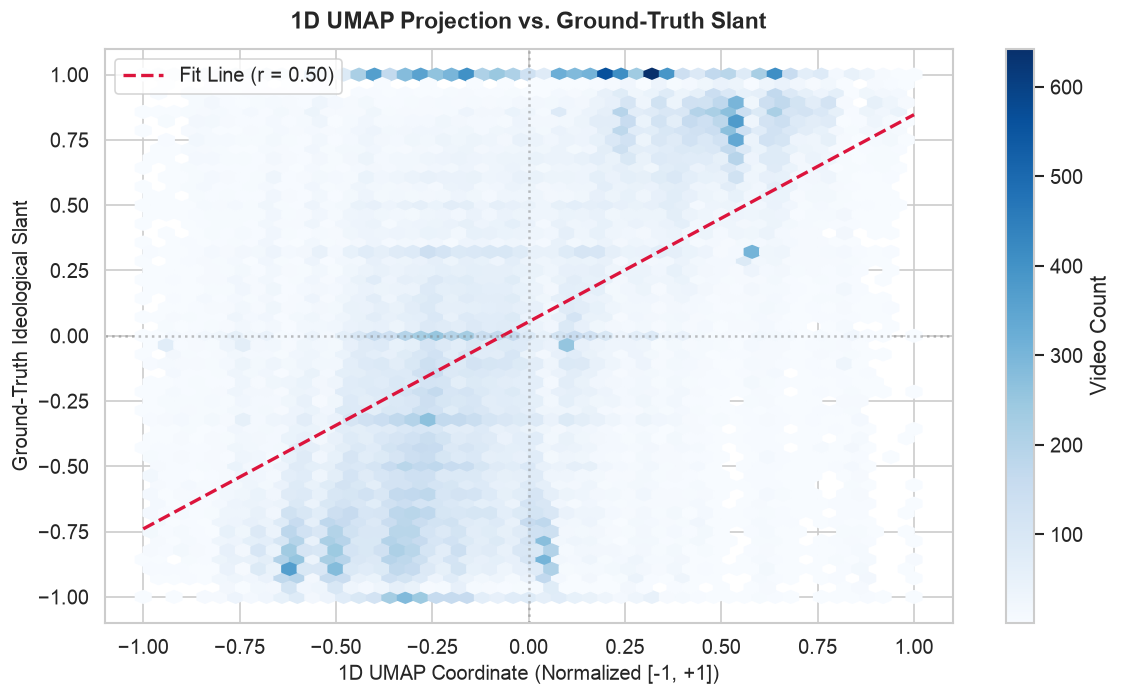

In [5]:
valid_mask = plot_df["slant"].notnull()
slant_valid = plot_df.loc[valid_mask, "slant"]
umap_valid = plot_df.loc[valid_mask, "umap_1d"]

pearson_r, p_pearson = stats.pearsonr(umap_valid, slant_valid)
spearman_rho, p_spearman = stats.spearmanr(umap_valid, slant_valid)

print("=== Correlation Analysis ===")
print(f"  • Pearson r:   {pearson_r:+.4f} (p = {p_pearson:.2e})")
print(f"  • Spearman ρ:  {spearman_rho:+.4f} (p = {p_spearman:.2e})")

# Hexbin / Scatter Correlation Plot
fig, ax = plt.subplots(figsize=(10, 6))
hb = ax.hexbin(
    plot_df["umap_1d"],
    plot_df["slant"],
    gridsize=50,
    cmap="Blues",
    mincnt=1
)
cb = plt.colorbar(hb, ax=ax, label="Video Count")

# Add linear trendline
m, b = np.polyfit(umap_valid, slant_valid, 1)
x_vals = np.linspace(plot_df["umap_1d"].min(), plot_df["umap_1d"].max(), 100)
ax.plot(x_vals, m * x_vals + b, color="crimson", linestyle="--", linewidth=2, label=f"Fit Line (r = {pearson_r:.2f})")

ax.set_title("1D UMAP Projection vs. Ground-Truth Slant", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("1D UMAP Coordinate (Normalized [-1, +1])", fontsize=12)
ax.set_ylabel("Ground-Truth Ideological Slant", fontsize=12)
ax.axhline(0, color="grey", linestyle=":", alpha=0.5)
ax.axvline(0, color="grey", linestyle=":", alpha=0.5)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

## 5. 1D Jitter Strip Plot
A continuous 1D visualization of all political videos, colored by their ideological slant.

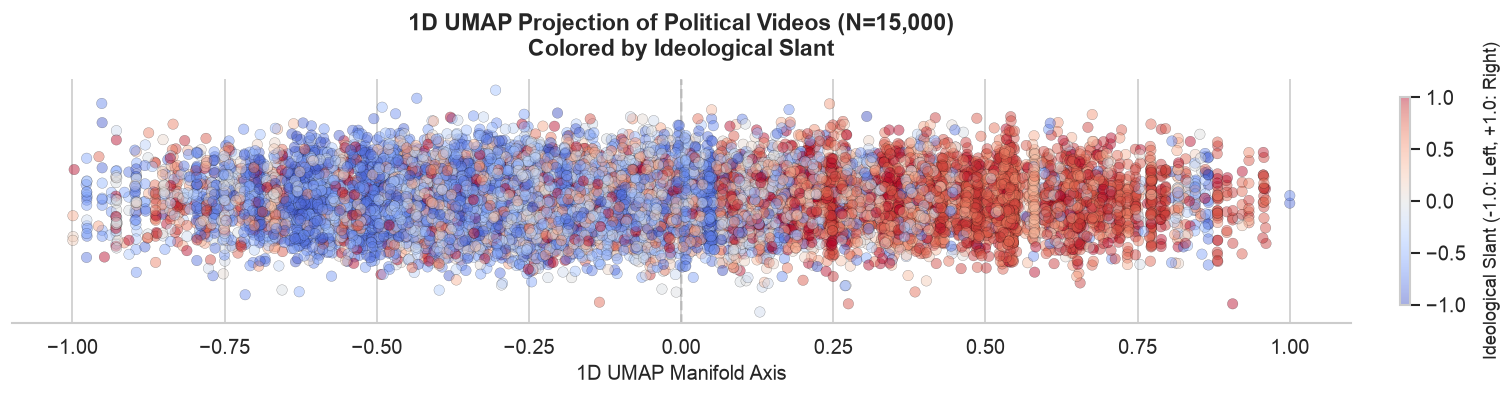

In [7]:
# Sample for clean visualization if dataset is large
PLOT_SAMPLE = min(15000, len(plot_df))
plot_sub = plot_df.sample(PLOT_SAMPLE, random_state=SEED).copy()

# Figure configuration for sleek 1D layout
fig, ax = plt.subplots(figsize=(14, 3.5))

# Random vertical jitter to reveal density
y_jitter = np.random.normal(loc=0, scale=0.02, size=len(plot_sub))

scatter = ax.scatter(
    plot_sub["umap_1d"],
    y_jitter,
    c=plot_sub["slant"],
    cmap="coolwarm",
    alpha=0.45,
    edgecolors="black",
    linewidth=0.2,
    s=40
)

cbar = plt.colorbar(scatter, ax=ax, shrink=0.85, pad=0.03)
cbar.set_label("Ideological Slant (-1.0: Left, +1.0: Right)", fontsize=11, labelpad=10)

ax.set_title(
    f"1D UMAP Projection of Political Videos (N={len(plot_sub):,})\nColored by Ideological Slant",
    fontsize=14,
    fontweight="bold",
    pad=14
)
ax.set_xlabel("1D UMAP Manifold Axis", fontsize=12)

# Hide meaningless vertical axis
ax.set_yticks([])
ax.spines["left"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)
ax.axvline(0, color="grey", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

## 6. Channel Ideological Distributions (KDE Density Plots)
Inspect how prominent news and commentary channels distribute along the 1D UMAP ideological spectrum.

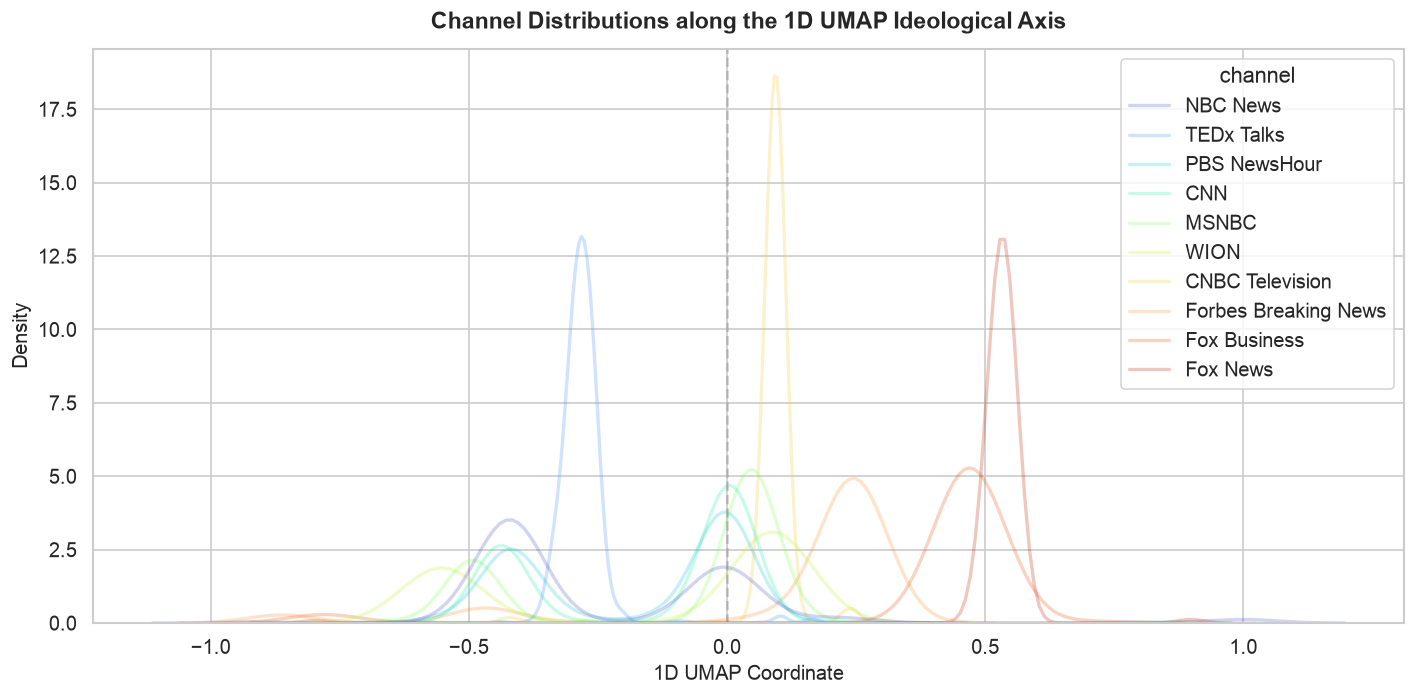

In [ ]:
# Filter for top channels with sufficient video volume
top_channel_counts = plot_df["channel"].value_counts()
candidate_channels = top_channel_counts.head(10).index.tolist()

df_channels = plot_df[plot_df["channel"].isin(candidate_channels)].copy()

# Order channels by median 1D UMAP coordinate
channel_order = (
    df_channels.groupby("channel")["umap_1d"]
    .median()
    .sort_values()
    .index.tolist()
)

fig, ax = plt.subplots(figsize=(12, 6))
sns.kdeplot(
    data=df_channels,
    x="umap_1d",
    hue="channel",
    hue_order=channel_order,
    common_norm=False,
    alpha=1,
    linewidth=2,
    palette="turbo",
    ax=ax
)

ax.set_title("Channel Distributions along the 1D UMAP Ideological Axis", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("1D UMAP Coordinate", fontsize=12)
ax.set_ylabel("Density", fontsize=12)
ax.axvline(0, color="grey", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

## 7. Semantic Inspection of Exemplar Videos
Inspect the most extreme Left-leaning, Centrist, and extreme Right-leaning videos along the 1D axis.

In [ ]:
print("="*90)
print("🔹 TOP 5 MOST LEFT-LEANING VIDEOS (Lowest 1D UMAP Coordinate)")
print("="*90)
left_videos = plot_df.sort_values("umap_1d").head(5)
for _, v in left_videos.iterrows():
    print(f"• [{v['umap_1d']:+.3f}] [{v['channel']}] {v['title'][:65]} (Slant: {v['slant']:+.2f})")

print("\n" + "="*90)
print("🔹 TOP 5 CENTRIST / MODERATE VIDEOS (Closest to Median UMAP Coordinate)")
print("="*90)
median_umap = plot_df["umap_1d"].median()
center_videos = plot_df.iloc[(plot_df["umap_1d"] - median_umap).abs().argsort()[:5]]
for _, v in center_videos.iterrows():
    print(f"• [{v['umap_1d']:+.3f}] [{v['channel']}] {v['title'][:65]} (Slant: {v['slant']:+.2f})")

print("\n" + "="*90)
print("🔹 TOP 5 MOST RIGHT-LEANING VIDEOS (Highest 1D UMAP Coordinate)")
print("="*90)
right_videos = plot_df.sort_values("umap_1d", ascending=False).head(5)
for _, v in right_videos.iterrows():
    print(f"• [{v['umap_1d']:+.3f}] [{v['channel']}] {v['title'][:65]} (Slant: {v['slant']:+.2f})")

## 8. Export 1D UMAP Coordinates to Parquet
Save the 1D UMAP coordinates alongside video metadata to `data/out/political_umap_1d.parquet`.

In [ ]:
out_path = OUT_DIR / "political_umap_1d.parquet"
df_out = pl.from_pandas(plot_df[["id", "channel", "title", "slant", "political_saliency", "umap_1d"]])
df_out.write_parquet(out_path)
print(f"Successfully saved 1D coordinates for {len(df_out):,} videos to: {out_path.name}")